# What happens to loan losses when more borrowers default?


I wanted to practise Python by modelling a simple financial
risk problem. I looked at what might happen if a lender
made 100 loans and some borrowers did not repay them.

I compared two examples: one where each borrower has a
5% chance of defaulting during the year, and another
where that chance is 10%.

Before running the simulation, I expected the second
example to produce higher average losses.

## My assumptions

To keep the model simple, I assumed:

- There are 100 loans of £1,000 each.
- If a borrower defaults, the lender gets £400 back
  and loses £600.
- Each borrower defaults independently of the others.
- Everyone has the same chance of defaulting within
  each example.
- Interest income and other costs are left out.

I chose these numbers for practice. They are not based
on real borrower data.

## What the code does

For each default probability, the code generates 10,000
possible one-year outcomes.

It then calculates the average loss and how often losses
are more than £6,000. I compare the simulated averages
with a calculation I can check by hand.

In [34]:
import pandas as pd
import numpy as np

# Shared assumptions for both scenarios
number_of_loans = 100
loan_amount = 1000
recovery_per_default = 400
loss_per_default = loan_amount - recovery_per_default

simulations = 10_000
loss_threshold = 6000

comparison_rng = np.random.default_rng(42)

# Simulate the 5% default scenario
defaults_5 = comparison_rng.binomial(
    n=number_of_loans,
    p=0.05,
    size=simulations,
)
losses_5 = defaults_5 * loss_per_default

# Simulate the 10% default scenario
defaults_10 = comparison_rng.binomial(
    n=number_of_loans,
    p=0.10,
    size=simulations,
)
losses_10 = defaults_10 * loss_per_default

# Collect the results in a table
comparison = pd.DataFrame(
    {
        "Scenario": ["5% default probability", "10% default probability"],
        "Theoretical mean loss (£)": [
            number_of_loans * 0.05 * loss_per_default,
            number_of_loans * 0.10 * loss_per_default,
        ],
        "Simulated mean loss (£)": [
            np.mean(losses_5),
            np.mean(losses_10),
        ],
        "Outcomes losing more than £6,000 (%)": [
            np.mean(losses_5 > loss_threshold) * 100,
            np.mean(losses_10 > loss_threshold) * 100,
        ],
    }
)

print(comparison.round(2).to_string(index=False))

               Scenario  Theoretical mean loss (£)  Simulated mean loss (£)  Outcomes losing more than £6,000 (%)
 5% default probability                     3000.0                  2988.54                                  1.24
10% default probability                     6000.0                  6014.88                                 42.52


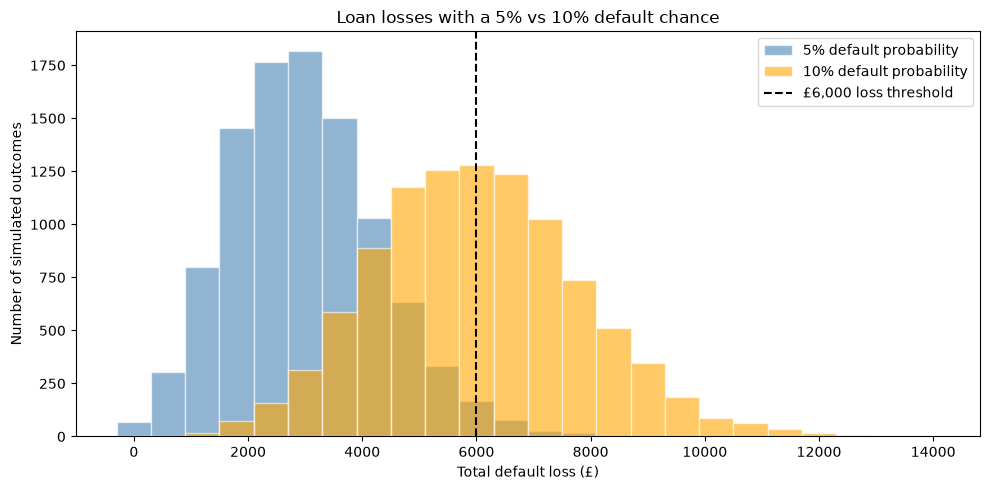

In [35]:
import matplotlib.pyplot as plt

# Use the same bins for both scenarios, spaced £600 apart
largest_loss = max(losses_5.max(), losses_10.max())

bin_edges = np.arange(
    -loss_per_default / 2,
    largest_loss + loss_per_default,
    loss_per_default,
)

plt.figure(figsize=(10, 5))

plt.hist(
    losses_5,
    bins=bin_edges,
    alpha=0.6,
    color="steelblue",
    edgecolor="white",
    label="5% default probability",
)

plt.hist(
    losses_10,
    bins=bin_edges,
    alpha=0.6,
    color="orange",
    edgecolor="white",
    label="10% default probability",
)

plt.axvline(
    loss_threshold,
    color="black",
    linestyle="--",
    label="£6,000 loss threshold",
)

plt.title("Loan losses with a 5% vs 10% default chance")
plt.xlabel("Total default loss (£)")
plt.ylabel("Number of simulated outcomes")
plt.legend()
plt.tight_layout()
plt.show()

## What I found

With a 5% default chance, the simulated average loss was
£2,988.54. With a 10% default chance, it was £6,014.88.

This matched my prediction that a higher default chance
would lead to higher average losses.

I also checked the averages by hand:

- 5% example: 100 × 0.05 × £600 = £3,000.
- 10% example: 100 × 0.10 × £600 = £6,000.

The simulated results were close to these values.

## Looking beyond the average

The proportion of outcomes with losses above £6,000
increased from 1.24% to 42.52%.

This showed me that looking at the average alone does
not tell the whole story. The chance of passing a
particular loss amount can change quite differently
from the average.

## Limitations

This is a simplified model, not a prediction of what
would happen at a real lender.

I assumed borrowers default independently. In reality,
several borrowers could face financial difficulties
at the same time.

I also gave every loan the same size and recovery amount.
The default probabilities were chosen for the exercise,
rather than estimated from data.
